In [1]:

import os, sys, random, platform
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import torch
from dotenv import load_dotenv

cwd = Path.cwd()
ROOT = cwd.parent if cwd.name == "notebooks" else cwd

DATA_DIR    = ROOT / "data"          # downloaded / processed data
MODELS_DIR  = ROOT / "models"        # fine-tuned models (retriever, ASR)
RESULTS_DIR = ROOT / "results"       # metric tables, plots
QDRANT_DIR  = ROOT / "qdrant_data"   # vector database

for d in (DATA_DIR, MODELS_DIR, RESULTS_DIR, QDRANT_DIR):
    d.mkdir(parents=True, exist_ok=True)

@dataclass(frozen=True)
class Config:
    seed: int = 42

    # dataset
    dataset_repo: str = "C4IR-RW/kinya-ag-retrieval"

    # chunking
    chunk_size: int = 500
    chunk_overlap: int = 50

    # retrieval
    base_embedding_model: str = "sentence-transformers/paraphrase-multilingual-mpnet-base-v2"
    finetuned_embedding_dir: Path = MODELS_DIR / "kinya-retriever"
    collection_name: str = "kinya_agri_docs"
    top_k: int = 5

    # LLM (generation)
    llm_model: str = "openai/gpt-oss-120b"
    llm_temperature: float = 0.0

CFG = Config()

def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(CFG.seed)
if torch.cuda.is_available():
    DEVICE = "cuda"
elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"

load_dotenv(ROOT / ".env")
GROQ_API_KEY = os.getenv("GROQ_API_KEY")

print(f"Python        : {sys.version.split()[0]} ({platform.system()})")
print(f"PyTorch       : {torch.__version__}")
print(f"Device        : {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))
print(f"Project root  : {ROOT}")
print(f"Seed          : {CFG.seed}")
print(f"Groq key      : {'found' if GROQ_API_KEY else 'MISSING -> add it to .env'}")
if DEVICE == "cpu":
    print("\nNote: no GPU detected. Fine-tuning will be slow on CPU; "
          "use Google Colab / Kaggle (free GPU) for notebooks 02 and 03.")


Python        : 3.13.3 (Windows)
PyTorch       : 2.9.1+cpu
Device        : cpu
Project root  : C:\Users\PC\Desktop\Mfasha chatbot\notebook
Seed          : 42
Groq key      : MISSING -> add it to .env

Note: no GPU detected. Fine-tuning will be slow on CPU; use Google Colab / Kaggle (free GPU) for notebooks 02 and 03.


In [2]:
# LOAD DATASET + BUILD TRAIN / DEV / TEST SPLITS

import csv
import pandas as pd
from huggingface_hub import hf_hub_download


def fetch(name: str) -> str:
    """Download one file of the dataset (cached after the first time)."""
    return hf_hub_download(CFG.dataset_repo, name, repo_type="dataset")


def read_lines(name: str, strip_quotes: bool = False, skip_blank: bool = True) -> list[str]:
    out = []
    with open(fetch(name), encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if skip_blank and not line:
                continue
            out.append(line.strip('"') if strip_quotes else line)
    return out


#  Passages 
passage_ids   = read_lines("rw_ag_retrieval_passage_id.txt")
passage_texts = read_lines("rw_ag_retrieval_passage_text.txt", strip_quotes=True)
assert len(passage_ids) == len(passage_texts), "passage ids and texts are misaligned"

pid2idx = {pid: i for i, pid in enumerate(passage_ids)}

# Questions 
# keep blank lines here so ids and texts stay aligned line by line
query_ids   = read_lines("rw_ag_retrieval_query_id.txt", skip_blank=False)
query_texts = read_lines("rw_ag_retrieval_query_text.txt", strip_quotes=True, skip_blank=False)
assert len(query_ids) == len(query_texts), "query ids and texts are misaligned"

qid2text = dict(zip(query_ids, query_texts))


# Labelled splits 
def load_split(split: str):
    """Returns (triplets, pairs) for 'train' | 'dev' | 'test'.
    triplets: question + good passage + bad passage  (used to train the retriever)
    pairs:    unique question + good passage         (used to evaluate it)
    """
    df = pd.read_csv(
        fetch(f"rw_ag_retrieval_qpntriplets_{split}.tsv"),
        sep="\t", header=None, names=["qid", "pos_pid", "neg_pid"],
        quoting=csv.QUOTE_NONE, dtype=str,
    )
    n_raw = len(df)
    df = df[df["qid"].isin(qid2text) & df["pos_pid"].isin(pid2idx)].reset_index(drop=True)

    df["question"] = df["qid"].map(qid2text)
    df["positive"] = df["pos_pid"].map(lambda p: passage_texts[pid2idx[p]])
    df["negative"] = df["neg_pid"].map(lambda p: passage_texts[pid2idx[p]] if p in pid2idx else None)

    pairs = (df[["qid", "pos_pid", "question", "positive"]]
             .drop_duplicates(["qid", "pos_pid"]).reset_index(drop=True))
    return df, pairs, n_raw


triplets, pairs, n_raw = {}, {}, {}
for split in ("train", "dev", "test"):
    triplets[split], pairs[split], n_raw[split] = load_split(split)


#  Dataset report 
summary = pd.DataFrame({
    s: {
        "triplet rows (raw)":   n_raw[s],
        "triplet rows (usable)": len(triplets[s]),
        "unique questions":     triplets[s]["qid"].nunique(),
        "question/passage pairs": len(pairs[s]),
        "unique positive passages": triplets[s]["pos_pid"].nunique(),
    } for s in triplets
})
print(summary.to_string(), "\n")

lens = pd.Series([len(t) for t in passage_texts])
print(f"passages: {len(passage_texts)} | characters: min {lens.min()}, "
      f"median {int(lens.median())}, mean {int(lens.mean())}, max {lens.max()}")
print(f"questions in total: {len(query_ids)}\n")

# Sanity checks (data leakage) 
q_train, q_dev, q_test = (set(triplets[s]["qid"]) for s in ("train", "dev", "test"))
print(f"train & dev : {len(q_train & q_dev)}")
print(f"train & test: {len(q_train & q_test)}")
print(f"dev   & test: {len(q_dev & q_test)}")

p_train, p_test = set(triplets["train"]["pos_pid"]), set(triplets["test"]["pos_pid"])
print(f"\nTest passages also seen in train: {len(p_test & p_train)} / {len(p_test)} "
      f"({len(p_test & p_train) / max(len(p_test), 1):.0%})")

for _, r in pairs["train"].sample(3, random_state=CFG.seed).iterrows():
    print("Q :", r["question"])
    print("A :", r["positive"][:250], "...\n")

#  Save processed data for the next notebooks 
pd.DataFrame({"pid": passage_ids, "text": passage_texts}).to_json(
    DATA_DIR / "passages.jsonl", orient="records", lines=True, force_ascii=False)
for s in triplets:
    triplets[s].to_csv(DATA_DIR / f"triplets_{s}.csv", index=False, encoding="utf-8")
    pairs[s].to_csv(DATA_DIR / f"pairs_{s}.csv", index=False, encoding="utf-8")
print(f"Saved processed data to {DATA_DIR}")


                            train    dev   test
triplet rows (raw)        1901200  19600  32900
triplet rows (usable)     1901200  19600  32900
unique questions            19012    196    329
question/passage pairs      19012    196    329
unique positive passages      941     10     20 

passages: 984 | characters: min 28, median 478, mean 584, max 2978
questions in total: 19537

train & dev : 0
train & test: 0
dev   & test: 0

Test passages also seen in train: 0 / 20 (0%)
Q : ni ibihe bimenyetso biranga inkwavu zafashwe n' indwara y' ubuheri bwo mu matwi y' inkwavu ?
A : Indwara y' Ubuheri bwo mu matwi y' inkwavu : Ikigero cy' inkwavu zifatwa : Inkwavu zose ; Ibimenyetso : Gucurika amatwi arwaye , kubyimba imiheha y' amatwi no kugira urukoko mu matwi ; Uburyo bwo kuyirwanya : Gukuraho urukoko , koza n' isabune n' ama ...

Q : Ni ibihe bimenyetso by indwara y amashuya cyangwa inkurikizi zayo nka ?
A : Indwara y' Amashuya cyangwa Inkurikizi mu nka : ...

Q : Ni gute wakirinda ikwirakwi

In [3]:

ROOT = cwd.parent if cwd.name in ("notebook", "notebooks") else cwd

# save ids only 
pd.DataFrame({"pid": passage_ids, "text": passage_texts}).to_json(
    DATA_DIR / "passages.jsonl", orient="records", lines=True, force_ascii=False)
pd.DataFrame({"qid": query_ids, "text": query_texts}).to_json(
    DATA_DIR / "queries.jsonl", orient="records", lines=True, force_ascii=False)
for s in triplets:
    triplets[s][["qid", "pos_pid", "neg_pid"]].to_csv(DATA_DIR / f"triplets_{s}.csv", index=False)
    pairs[s][["qid", "pos_pid"]].to_csv(DATA_DIR / f"pairs_{s}.csv", index=False)
print(f"Saved processed data to {DATA_DIR}")

Saved processed data to C:\Users\PC\Desktop\Mfasha chatbot\notebook\data


In [4]:
!pip install rank_bm25 sentence-transformers

  Using cached sentence_transformers-6.1.0-py3-none-any.whl.metadata (20 kB)
  Using cached transformers-5.19.0-py3-none-any.whl.metadata (32 kB)
  Using cached tokenizers-0.23.3-cp310-abi3-win_amd64.whl.metadata (10 kB)
  Using cached huggingface_hub-1.33.0-py3-none-any.whl.metadata (16 kB)
  Using cached httpx-0.28.1-py3-none-any.whl.metadata (7.1 kB)
  Using cached typer-0.27.3-py3-none-any.whl.metadata (16 kB)
Using cached sentence_transformers-6.1.0-py3-none-any.whl (740 kB)
Using cached huggingface_hub-1.33.0-py3-none-any.whl (846 kB)
Using cached tokenizers-0.23.3-cp310-abi3-win_amd64.whl (2.9 MB)
Using cached transformers-5.19.0-py3-none-any.whl (12.6 MB)
Using cached httpx-0.28.1-py3-none-any.whl (73 kB)
Using cached typer-0.27.3-py3-none-any.whl (123 kB)



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
# BASELINES 

import re
import numpy as np
import pandas as pd
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer

# Setup: dev questions and the index of their correct passage
dev     = pairs["dev"].reset_index(drop=True)
queries = dev["question"].tolist()
gold    = np.array([pid2idx[p] for p in dev["pos_pid"]])
print(f"dev questions: {len(queries)} | searching {len(passage_texts)} passages")


# Scoring helpers
def tok(text: str) -> list[str]:
    return re.findall(r"\w+", text.lower())     

def to_rank(S):
    """score matrix -> rank matrix (1 = best), per query."""
    return np.argsort(np.argsort(-S, axis=1), axis=1) + 1

def rrf(score_mats, weights, k=60):
    """Reciprocal Rank Fusion over several score matrices."""
    return sum(w / (k + to_rank(S)) for S, w in zip(score_mats, weights))

def gold_ranks(S, gold):
    g = S[np.arange(len(S)), gold][:, None]
    return (S >= g).sum(axis=1)                 
def evaluate(S, name):
    r = gold_ranks(S, gold)
    row = {"method": name}
    for k in (1, 5, 10, 20):
        row[f"Recall@{k}"] = (r <= k).mean()
    row["MRR@10"] = np.where(r <= 10, 1 / r, 0).mean()
    # dev has only 10 distinct passages, so also average per passage (every passage counts equally)
    row["Recall@1 (per-passage avg)"] = pd.Series(r <= 1).groupby(gold).mean().mean()
    return row


# BM25
bm25   = BM25Okapi([tok(t) for t in passage_texts])
S_bm25 = np.vstack([bm25.get_scores(tok(q)) for q in queries])

# Base multilingual embeddings 
emb_file = RESULTS_DIR / "base_passage_emb.npy"
model = SentenceTransformer(CFG.base_embedding_model, device=DEVICE)
model.max_seq_length = 256                        # default is 128, which cuts long passages

if emb_file.exists():
    P = np.load(emb_file)
else:
    P = model.encode(passage_texts, batch_size=16, normalize_embeddings=True, show_progress_bar=True)
    np.save(emb_file, P)

Q = model.encode(queries, batch_size=32, normalize_embeddings=True, show_progress_bar=False)
S_emb = Q @ P.T

# 3) Hybrid (RRF) with different weights on the embedding side
S_h_equal = rrf([S_bm25, S_emb], [1.0, 1.0])
S_h_half  = rrf([S_bm25, S_emb], [1.0, 0.5])
S_h_light = rrf([S_bm25, S_emb], [1.0, 0.25])

# Results table
results = pd.DataFrame([
    evaluate(S_bm25,   "BM25"),
    evaluate(S_emb,    "Base embeddings (mpnet)"),
    evaluate(S_h_equal,"Hybrid RRF 1 : 1"),
    evaluate(S_h_half, "Hybrid RRF 1 : 0.5"),
    evaluate(S_h_light,"Hybrid RRF 1 : 0.25"),
]).set_index("method")

print("\nBASELINES ON DEV")
print(results.round(3).to_string())

# Per-passage breakdown (Recall@1), to see which passages fail
r_bm, r_em = gold_ranks(S_bm25, gold), gold_ranks(S_emb, gold)
by_passage = pd.DataFrame({
    "pid": dev["pos_pid"],
    "bm25_hit@1": r_bm <= 1,
    "emb_hit@1":  r_em <= 1,
    "passage_chars": [len(passage_texts[i]) for i in gold],
}).groupby("pid").agg(questions=("bm25_hit@1", "size"),
                      bm25_R1=("bm25_hit@1", "mean"),
                      emb_R1=("emb_hit@1", "mean"),
                      passage_chars=("passage_chars", "first"))
print("\nPER DEV PASSAGE")
print(by_passage.round(2).to_string())

# Save
results.round(4).to_csv(RESULTS_DIR / "baselines_dev.csv")
print(f"\nSaved {RESULTS_DIR / 'baselines_dev.csv'}")

dev questions: 196 | searching 984 passages


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

XLMRobertaModel LOAD REPORT from: sentence-transformers/paraphrase-multilingual-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Batches:   0%|          | 0/62 [00:00<?, ?it/s]


BASELINES ON DEV
                         Recall@1  Recall@5  Recall@10  Recall@20  MRR@10  Recall@1 (per-passage avg)
method                                                                                               
BM25                        0.520     0.776      0.857      0.878   0.627                       0.569
Base embeddings (mpnet)     0.102     0.143      0.148      0.179   0.115                       0.174
Hybrid RRF 1 : 1            0.189     0.327      0.459      0.791   0.252                       0.244
Hybrid RRF 1 : 0.5          0.214     0.510      0.730      0.862   0.340                       0.264
Hybrid RRF 1 : 0.25         0.296     0.653      0.832      0.872   0.442                       0.329

PER DEV PASSAGE
          questions  bm25_R1  emb_R1  passage_chars
pid                                                
A014T618         26     0.23    0.00            195
A344T775         25     0.68    0.08            237
A374T805         23     0.96    0.00       

C:\Users\PC\AppData\Local\Temp\ipykernel_14880\451489514.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=20, ha="right")


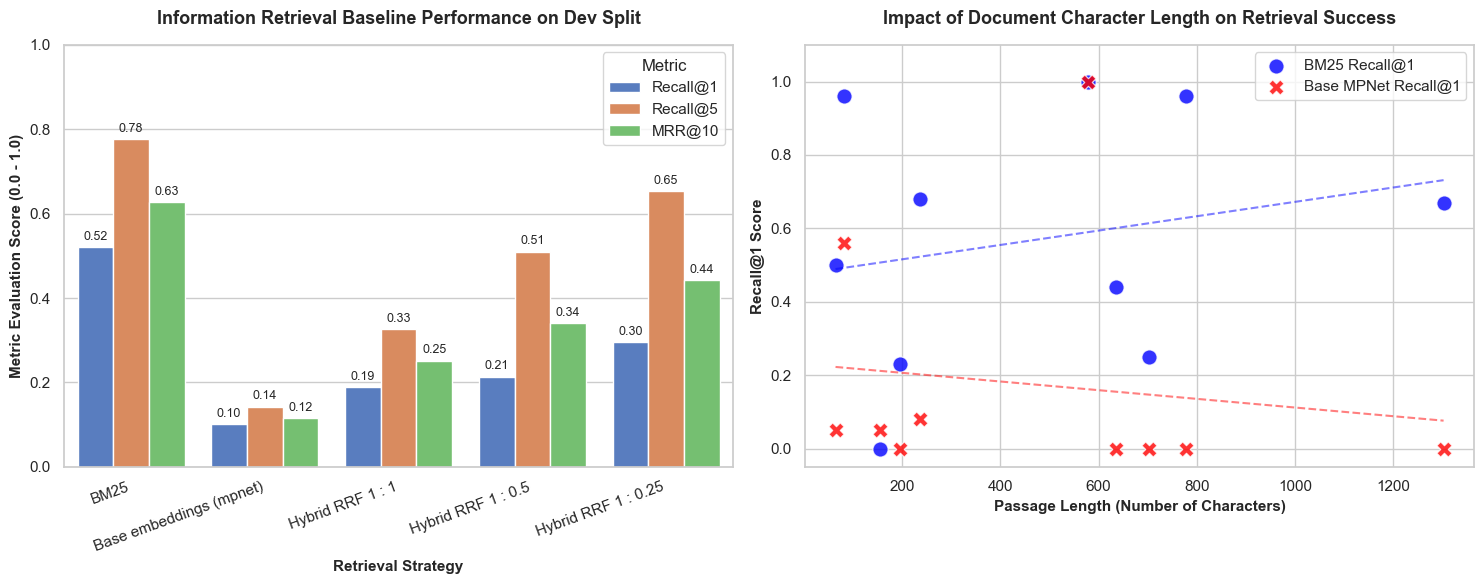

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Recreate the dataframes from your stdout text
metrics_data = {
    "method": [
        "BM25", "Base embeddings (mpnet)", 
        "Hybrid RRF 1 : 1", "Hybrid RRF 1 : 0.5", "Hybrid RRF 1 : 0.25"
    ],
    "Recall@1": [0.520, 0.102, 0.189, 0.214, 0.296],
    "Recall@5": [0.776, 0.143, 0.327, 0.510, 0.653],
    "Recall@10": [0.857, 0.148, 0.459, 0.730, 0.832],
    "MRR@10": [0.627, 0.115, 0.252, 0.340, 0.442]
}
df_metrics = pd.DataFrame(metrics_data).set_index("method")

passage_data = {
    "pid": ["A014T618", "A344T775", "A374T805", "A424T233", "A477T286", "A663T476", "A741T557", "A742T558", "A801T839", "A930T974"],
    "bm25_R1": [0.23, 0.68, 0.96, 0.25, 0.44, 0.96, 0.50, 0.00, 0.67, 1.00],
    "emb_R1": [0.00, 0.08, 0.00, 0.00, 0.00, 0.56, 0.05, 0.05, 0.00, 1.00],
    "passage_chars": [195, 237, 779, 703, 635, 81, 64, 154, 1303, 579]
}
df_passage = pd.DataFrame(passage_data)

# Set scientific plotting style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# ---- PLOT 1: Baseline Methods Comparison Bar Chart ----
df_plot1 = df_metrics[["Recall@1", "Recall@5", "MRR@10"]].reset_index()
df_melted = df_plot1.melt(id_vars="method", var_name="Metric", value_name="Score")

sns.barplot(
    data=df_melted, x="method", y="Score", hue="Metric", 
    palette="muted", ax=axes[0]
)
axes[0].set_title("Information Retrieval Baseline Performance on Dev Split", fontsize=13, fontweight='bold', pad=15)
axes[0].set_xlabel("Retrieval Strategy", fontsize=11, fontweight='bold')
axes[0].set_ylabel("Metric Evaluation Score (0.0 - 1.0)", fontsize=11, fontweight='bold')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=20, ha="right")
axes[0].set_ylim(0, 1.0)

# Add value tags over bars for academic precision
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.2f', padding=3, fontsize=9)

# ---- PLOT 2: Text Length vs Retrieval Accuracy Scatter Plot ----
sns.scatterplot(
    data=df_passage, x="passage_chars", y="bm25_R1", 
    color="blue", s=120, label="BM25 Recall@1", marker="o", alpha=0.8, ax=axes[1]
)
sns.scatterplot(
    data=df_passage, x="passage_chars", y="emb_R1", 
    color="red", s=120, label="Base MPNet Recall@1", marker="X", alpha=0.8, ax=axes[1]
)

# Add trendlines to reveal document length bias
sns.regsubplot = np.poly1d(np.polyfit(df_passage["passage_chars"], df_passage["bm25_R1"], 1))
x_range = np.linspace(df_passage["passage_chars"].min(), df_passage["passage_chars"].max(), 100)
axes[1].plot(x_range, sns.regsubplot(x_range), color="blue", linestyle="--", alpha=0.5)

sns.regsubplot_emb = np.poly1d(np.polyfit(df_passage["passage_chars"], df_passage["emb_R1"], 1))
axes[1].plot(x_range, sns.regsubplot_emb(x_range), color="red", linestyle="--", alpha=0.5)

axes[1].set_title("Impact of Document Character Length on Retrieval Success", fontsize=13, fontweight='bold', pad=15)
axes[1].set_xlabel("Passage Length (Number of Characters)", fontsize=11, fontweight='bold')
axes[1].set_ylabel("Recall@1 Score", fontsize=11, fontweight='bold')
axes[1].set_ylim(-0.05, 1.1)
axes[1].legend(loc="upper right", frameon=True)

plt.tight_layout()

# Save figure directly to your academic results folder
plt.savefig(r"C:\Users\PC\Desktop\Mfasha chatbot\results\baseline_analysis_plots.png", dpi=300)
plt.show()
